# 05 - Belauri forward simulations on the real prepared region

**Real geography; synthetic emissions and meteorology.** The municipality polygon, the road / built-up / facility geometry and the position of the external patch are real (prepared in `data/belauri`). Every emission rate, the external onset and every wind is a **synthetic, prescribed** demonstration value; K, lambda, H are nominal. The DEM, hillshade and slope are **plotting-only context**: no solver input reads them.

**Bounded run.** 500 m grid, standard (8 km) outer domain, four winds, a 2 km small outer domain, and a mesh comparison (500 m dt 100 s, 500 m dt 50 s, 250 m dt 50 s). The 250 m comparison uses a **short window** (T = 2 h, 3 km buffer crop, the smoke profile) to stay within minutes; the full 8 h comparison is produced by the command-line run `python -m pravah benchmark --config configs/belauri_forward.json`.

Terms: *local* = emitted inside the municipality (road + built-up layers), *external* = the external patch (outside it). Origin follows the source layer, not where the mass is now. Local layers are clipped to the polygon, boundary cells count in full, so ~5 % of a local layer's mass lies in cells that straddle the border (documented tolerance).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from pravah.config import load_config
from pravah import belauri as B
from pravah.geo.scenarios import numerical_diffusion_estimate, LABEL
%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
T0 = time.perf_counter()
root = Path.cwd()
while not (root / "configs" / "belauri_forward.json").exists() and root != root.parent:
    root = root.parent
cfg = load_config(root / "configs" / "belauri_forward.json")
cfg["manifest_note"] = "path resolved by pravah"
cfg["wind"]["run"] = ["from_west_southwest", "from_north", "reversal", "channelled_demo"]
study = B.Study(cfg)
print(LABEL)

Real geography; synthetic emissions and meteorology.


## 1. Provenance panel (from the manifest)

In [2]:
m = study.full.manifest
ds = m["datasets"]
prov = pd.DataFrame([{"id": d["id"], "role": d.get("role"), "licence": str(d["license"])[:70], "retrieved_utc": d["retrieved_utc"]} for d in ds])
display(prov)
print("boundary_status:", m["boundary_status"], "| CRS EPSG", m["crs"]["epsg"], "| manifest sha256", study.manifest_sha256[:16], "...")
print("processed-array licences:", sorted({str(p["license"])[:60] for p in m["processed"]})[:3])
print("resolutions (m):", m["grid_config"]["resolutions_m"], "| buffer (m):", m["grid_config"]["buffer_m"])
print("warnings:"); [print("  -", w) for w in m["warnings"]]
print("assumptions:"); [print("  -", a) for a in m["assumptions"]]
ep = m["external_patch"]
print(f"external patch: centre (local m) {ep['centre_local_m']}, sigma {ep['sigma_m']} m, {ep['distance_to_polygon_km']:.2f} km from the polygon; 'international' is NOT asserted (patch is in no ADM0 polygon).")

,id,role,licence,retrieved_utc
0,geoBoundaries:NPL-ADM3:NPL-ADM3-92635248,study,Creative Commons Attribution-ShareAlike 4.0 In...,2026-10-10T15:40:38+00:00
1,geoBoundaries:NPL-ADM2:NPL-ADM2-79688334,adm2,Public Domain,2026-10-10T15:40:40+00:00
2,geoBoundaries:NPL-ADM0:NPL-ADM0-63295607,adm0_NPL,Creative Commons Attribution 4.0 International...,2026-10-10T15:40:41+00:00
3,geoBoundaries:IND-ADM0:IND-ADM0-67634026,adm0_IND,CC0 1.0 Universal (CC0 1.0) Public Domain Dedi...,2026-10-10T15:40:42+00:00
4,"nominatim:Belauri, Kanchanpur, Nepal",nominatim,ODbL 1.0 (https://opendatacommons.org/licenses...,2026-10-10T15:40:43+00:00
5,overpass:osm_roads,osm_roads,ODbL 1.0 (https://opendatacommons.org/licenses...,2026-10-10T16:56:34+00:00
6,overpass:osm_buildings,osm_buildings,ODbL 1.0 (https://opendatacommons.org/licenses...,2026-10-10T16:56:34+00:00
7,overpass:osm_landuse,osm_landuse,ODbL 1.0 (https://opendatacommons.org/licenses...,2026-10-10T16:56:34+00:00
8,overpass:osm_amenity,osm_amenity,ODbL 1.0 (https://opendatacommons.org/licenses...,2026-10-10T16:56:34+00:00
9,Copernicus GLO-30 DSM: Copernicus_DSM_COG_10_N...,dem,Copernicus DEM GLO-30 (ESA/EU Copernicus progr...,2026-10-10T17:07:43+00:00


boundary_status: verified | CRS EPSG 32644 | manifest sha256 7ff8b8b9b1615a87 ...
processed-array licences: ['Copernicus DEM GLO-30 (ESA/EU Copernicus programme licence: ']
resolutions (m): [500.0, 250.0] | buffer (m): 8000.0
warnings:
  - OSM completeness is unknown: absent roads/buildings in the data are mapping gaps, not zero sources.
  - external patch centre lies outside the home ADM0 polygon near the shared boundary but inside no neighbour ADM0 polygon (the neighbour outline is coarse): class 'external_outside_home'; 'international' is not asserted
assumptions:
  - synthetic spatial prior (real geometry, assumed emission pattern; not measured emissions)
  - DEM is a surface model used as context only unless a layer alters source geometry
  - local sources are clipped to the polygon; boundary cells count by area fraction
external patch: centre (local m) [10609.022822454048, 14415.55935851112], sigma 1000.0 m, 2.92 km from the polygon; 'international' is NOT asserted (patch is in n

## 2. The region: boundary, surrounding domain, hillshade, N-S profile, sources, report points

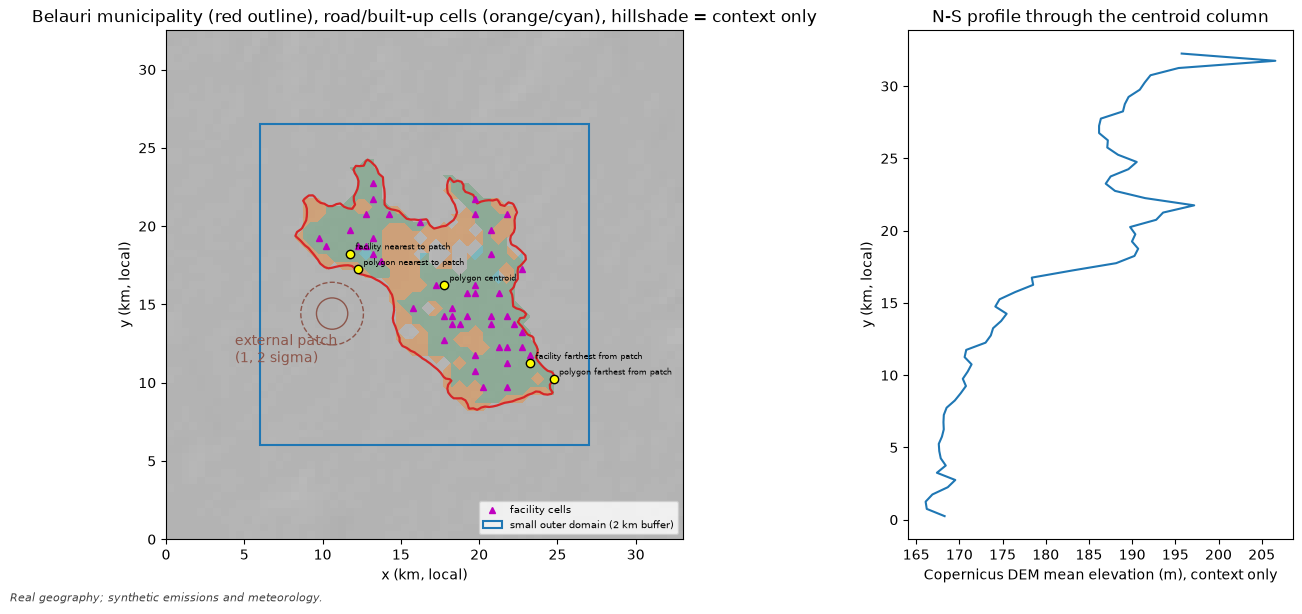

domain 66 x 65 cells of 500.0 m = 33.0 x 32.5 km; polygon cells (500 m): 584
                          label        x        y  distance_to_patch_m
0      polygon_nearest_to_patch  12250.0  17250.0               3275.0
1   polygon_farthest_from_patch  24750.0  10250.0              14742.0
2     facility_nearest_to_patch  11750.0  18250.0               4001.0
3  facility_farthest_from_patch  23250.0  11250.0              13031.0
4              polygon_centroid  17750.0  16250.0               7373.0


In [3]:
fig = B.fig_overview(study); plt.show()
lv = study.region.level(500.0)
print("domain", lv.grid.nx, "x", lv.grid.ny, "cells of", lv.grid.dx, "m =", lv.grid.lx / 1000, "x", lv.grid.ly / 1000, "km; polygon cells (500 m):", lv.info["polygon_cells"])
print(pd.DataFrame(study.points).round(0))

The hillshade and the elevation profile are drawn for orientation only; relief in the municipality is about 37 m, so even a physical use would be weak. **No number below depends on them** (checked in section 9).

## 3. Choices: domain and time
Travel distance u T = 1.5 m/s x 28800 s = 43 km (larger than the 33 km domain: plumes can leave it, which is fine with open boundaries); physical diffusion length sqrt(2 K T) = 2.4 km; removal lifetime 1/lambda = 6 h; Courant number u dt / dx = 0.3 at 500 m / 100 s and 0.3 at 250 m / 50 s.

In [4]:
u, K, T = study.speed, study.K, study.T
print(f"u*T = {u*T/1000:.0f} km | sqrt(2KT) = {np.sqrt(2*K*T)/1000:.1f} km | 1/lambda = {1/study.lam/3600:.0f} h | Courant 500 m: {u*100/500:.2f}, 250 m: {u*50/250:.2f}")
rows = [{"mesh": f"{dx:g} m, dt {dt:g} s", "Pe=u dx/K": u*dx/K, "excess K_eff/K-1": numerical_diffusion_estimate(u, dx, dt, K)} for dx, dt in ((500, 100), (500, 50), (250, 50))]
display(pd.DataFrame(rows).round(2))
print("The discretisation adds several times the nominal K = 100 m^2/s at these cells; K is a NOMINAL input, the effective spreading is larger (estimate exact for axis-aligned wind).")

u*T = 43 km | sqrt(2KT) = 2.4 km | 1/lambda = 6 h | Courant 500 m: 0.30, 250 m: 0.30


,mesh,Pe=u dx/K,excess K_eff/K-1
0,"500 m, dt 100 s",7.50,3.88
1,"500 m, dt 50 s",7.50,3.32
2,"250 m, dt 50 s",3.75,1.53


The discretisation adds several times the nominal K = 100 m^2/s at these cells; K is a NOMINAL input, the effective spreading is larger (estimate exact for axis-aligned wind).


## 4. Local-only, external-only and combined fields for several winds

In [5]:
t0 = time.perf_counter()
res = {n: study.wind_result(n) for n in cfg["wind"]["run"]}
print(f"solved in {time.perf_counter()-t0:.0f} s")
rows = []
for n, r in res.items():
    s = r.summary
    rows.append({"wind": n, "local peak": s["local"]["peak"], "external peak": s["external"]["peak"], "combined peak": s["total"]["peak"],
                 "combined regional mean": s["total"]["time_mean_regional_mean"], "external fraction": s["external_fraction"],
                 "max |direct - (local+external)|": r.consistency["max_abs_err_direct_vs_tag_sum"], "budget residual": r.consistency["max_rel_budget_residual"]})
display(pd.DataFrame(rows).round(4))
print("emission amplitudes (SYNTHETIC, ug/s):", study.amplitudes)

solved in 123 s


,wind,local peak,external peak,combined peak,combined regional mean,external fraction,max |direct - (local+external)|,budget residual
0,from_west_southwest,0.2266,0.1587,0.3010,0.1245,0.2207,0.0,0.0
1,from_north,0.2614,0.0003,0.2614,0.1098,0.0001,0.0,0.0
2,reversal,0.3854,0.1582,0.3950,0.1457,0.0507,0.0,0.0
3,channelled_demo,0.2684,0.2033,0.3700,0.1524,0.1940,0.0,0.0


emission amplitudes (SYNTHETIC, ug/s): {'road': 1500000.0, 'builtup': 1000000.0, 'external': 500000.0}


The first column pair checks the linear tag machinery: the combined direct solve equals local + external to round-off, and the mass budget closes. All winds are prescribed and synthetic; `channelled_demo` is a divergence-free stream function (uniform wind plus a Gaussian eddy), **not derived from the terrain**.

## 5. Snapshots (common colour scale) and an animation

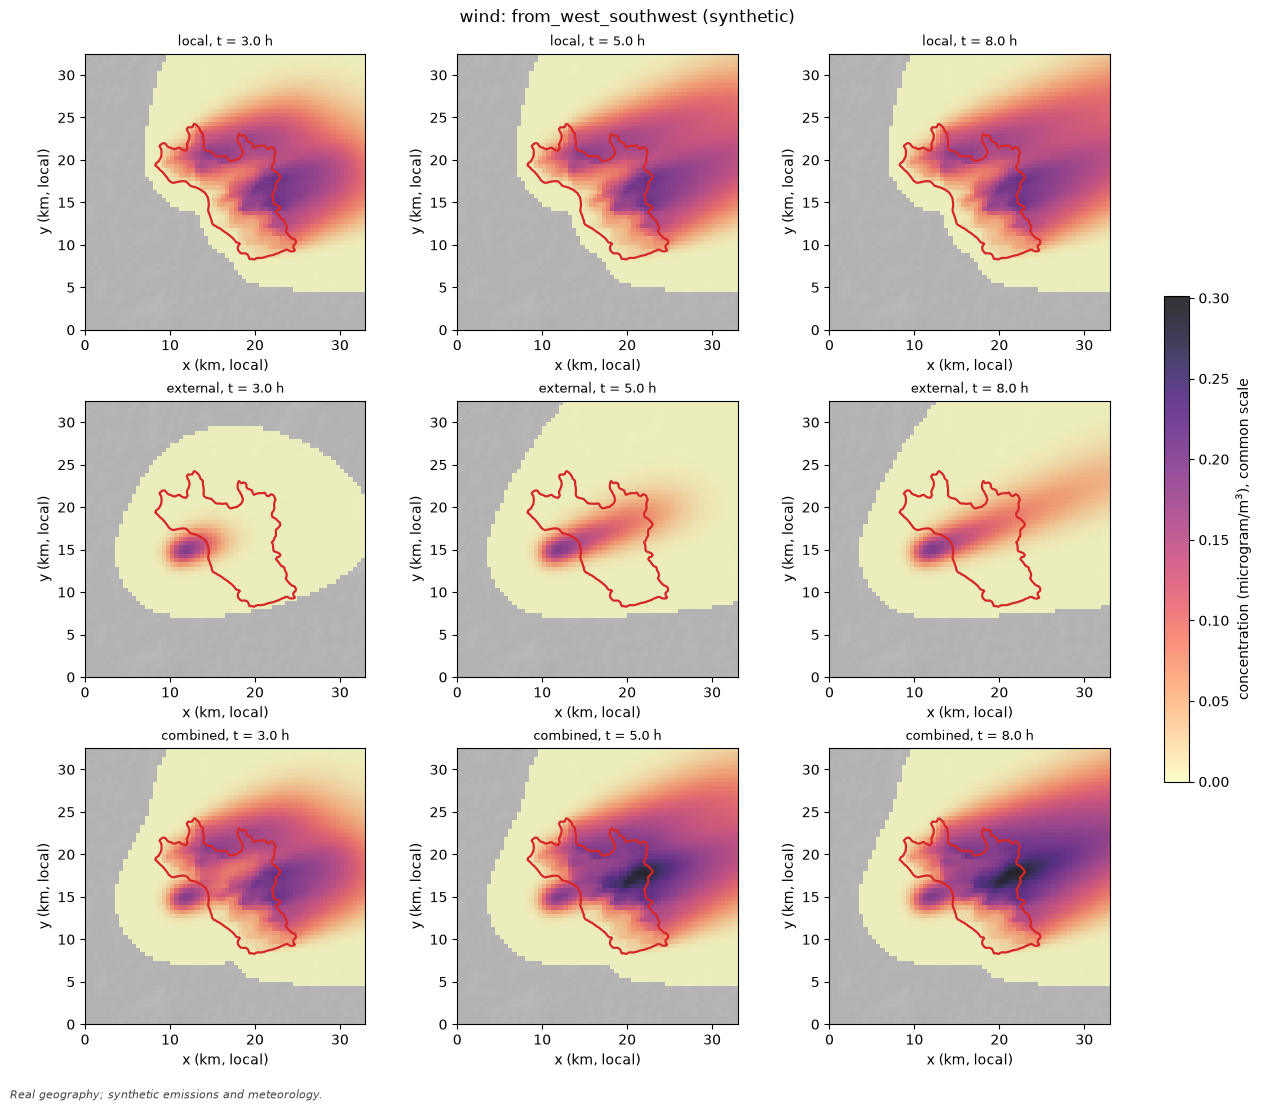

In [6]:
ref = res["from_west_southwest"]
fig = B.fig_contributions(study, ref, [10800.0, 18000.0, 28800.0]); plt.show()

In [7]:
try:
    from IPython.display import HTML
    anim = B.animate_on_map(study, ref, "total", max_frames=49)
    html = anim.to_jshtml(); plt.close("all")
    display(HTML(html))
except Exception as exc:
    print("animation skipped:", type(exc).__name__, exc)

## 6. Arrival of the external tag, source contributions and regional summaries

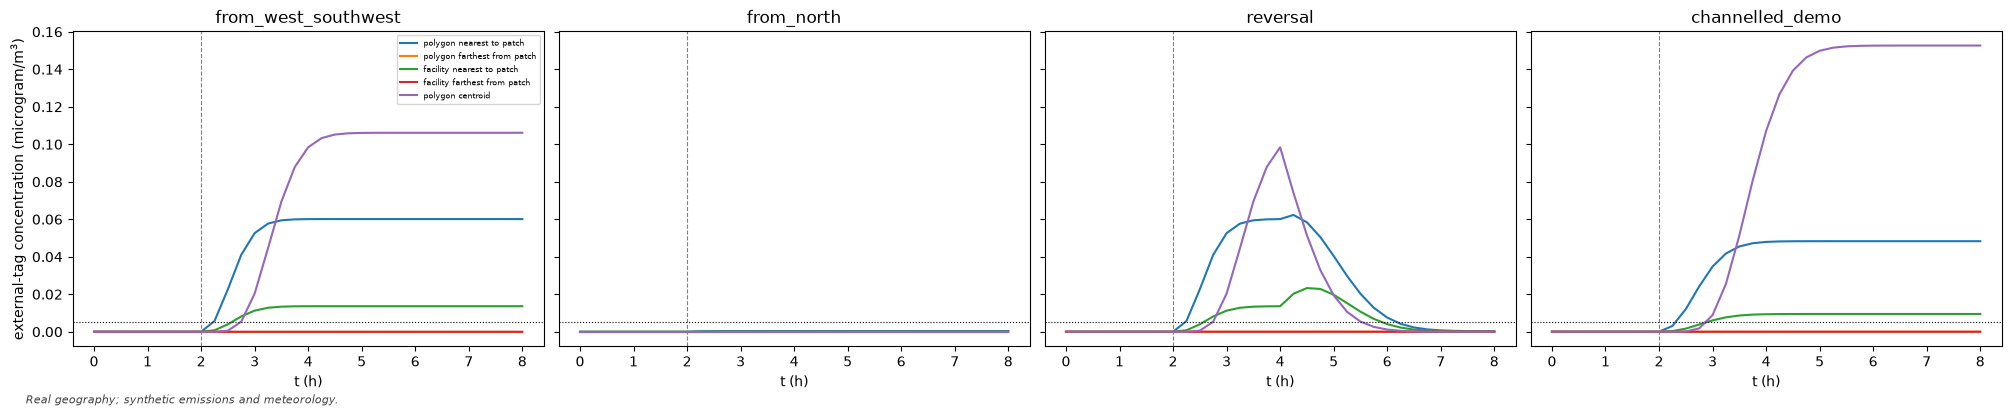

,wind,point,arrival_s,arrival_after_onset_s,max_external
0,from_west_southwest,polygon_nearest_to_patch,7988.8147,788.8147,0.0601
1,from_west_southwest,polygon_farthest_from_patch,NaN,NaN,0.0000
2,from_west_southwest,facility_nearest_to_patch,9220.2249,2020.2249,0.0136
3,from_west_southwest,facility_farthest_from_patch,NaN,NaN,0.0000
4,from_west_southwest,polygon_centroid,9826.8216,2626.8216,0.1061
5,from_north,polygon_nearest_to_patch,NaN,NaN,0.0003
6,from_north,polygon_farthest_from_patch,NaN,NaN,0.0000
7,from_north,facility_nearest_to_patch,NaN,NaN,0.0000
8,from_north,facility_farthest_from_patch,NaN,NaN,0.0000
9,from_north,polygon_centroid,NaN,NaN,0.0000


arrival = first time the external-tag concentration exceeds 0.005 ug/m3 (output interval 900 s, linear interpolation); the patch switches on at 7200 s; blank = never reached in this run.


In [8]:
fig = B.fig_arrival(study, list(res.values())); plt.show()
arr = pd.DataFrame([{"wind": n, **a} for n, r in res.items() for a in r.arrival])
display(arr[["wind", "point", "arrival_s", "arrival_after_onset_s", "max_external"]].round(4))
print(f"arrival = first time the external-tag concentration exceeds {study.arrival_level} ug/m3 (output interval {study.out_dt:.0f} s, linear interpolation); the patch switches on at {study.onset_s:.0f} s; blank = never reached in this run.")

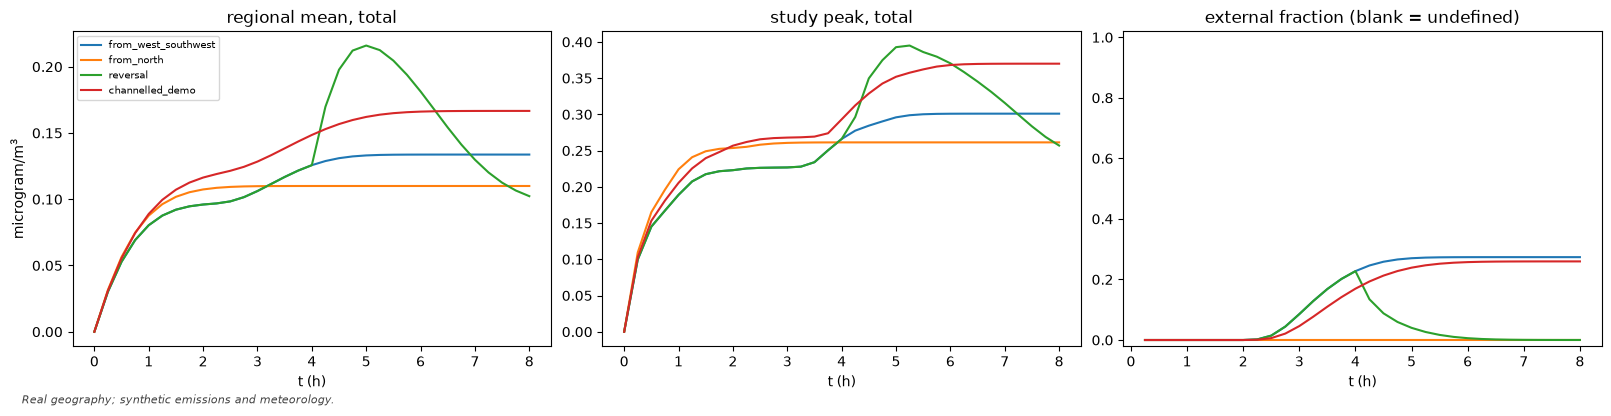

,road,builtup,external_patch
"peak anywhere, one source at a time (ug/m3)",0.1226,0.1092,0.1992


In [9]:
fig = B.fig_regional(list(res.values())); plt.show()
lay = res["from_west_southwest"]
comp = pd.DataFrame({k: [lay.resp.g[j][lay.resp.times >= study.t_exclude].max() * lay.case.theta[j]] for j, k in enumerate(lay.resp.param_names)}, index=["peak anywhere, one source at a time (ug/m3)"])
display(comp.round(4))

## 7. Smaller and larger outer domain

In [10]:
t0 = time.perf_counter()
buf = float(cfg["region"]["small_buffer_m"])
orows, oarr = [], []
for n in ("from_west_southwest", "reversal"):
    row, arr_, f, case = B.outer_domain_rows(study, res[n], buf)
    orows.append(row); oarr += arr_
display(pd.DataFrame(orows)[["wind", "buffer_m", "n_cells_small", "n_cells_standard", "peak_change_pct", "mean_change_pct", "rmse_total_rel_peak", "max_abs_diff_whole_small_domain"]].round(5))
display(pd.DataFrame(oarr).round(1))
print(f"{time.perf_counter()-t0:.0f} s. Differences are the effect of the open boundary being closer. They vanish for the steady WSW wind (plumes leave through the boundary) but are not small for the reversal wind (about -10 % in the regional mean): mass that left a smaller domain cannot return when the wind turns.")

,wind,buffer_m,n_cells_small,n_cells_standard,peak_change_pct,mean_change_pct,rmse_total_rel_peak,max_abs_diff_whole_small_domain
0,from_west_southwest,2000.0,1722,4290,-0.00000,-0.00005,0.0000,0.00086
1,reversal,2000.0,1722,4290,-0.91478,-10.50433,0.0693,0.15808


,wind,buffer_m,point,arrival_standard_s,arrival_small_s,difference_s
0,from_west_southwest,2000.0,polygon_nearest_to_patch,7988.8,7988.8,-0.0
1,from_west_southwest,2000.0,polygon_farthest_from_patch,NaN,NaN,NaN
2,from_west_southwest,2000.0,facility_nearest_to_patch,9220.2,9220.2,-0.0
3,from_west_southwest,2000.0,facility_farthest_from_patch,NaN,NaN,NaN
4,from_west_southwest,2000.0,polygon_centroid,9826.8,9826.8,-0.0
5,reversal,2000.0,polygon_nearest_to_patch,7988.8,7988.8,-0.0
6,reversal,2000.0,polygon_farthest_from_patch,NaN,NaN,NaN
7,reversal,2000.0,facility_nearest_to_patch,9220.2,9220.2,-0.0
8,reversal,2000.0,facility_farthest_from_patch,NaN,NaN,NaN
9,reversal,2000.0,polygon_centroid,9826.8,9826.8,-0.0


11 s. Differences are the effect of the open boundary being closer. They vanish for the steady WSW wind (plumes leave through the boundary) but are not small for the reversal wind (about -10 % in the regional mean): mass that left a smaller domain cannot return when the wind turns.


## 8. Two mesh resolutions and the time step

In [11]:
t0 = time.perf_counter()
scfg = load_config(root / "configs" / "belauri_forward_smoke.json")   # short window: T = 2 h, 3 km buffer crop
sstudy = B.Study(scfg)
base = sstudy.wind_result("from_west_southwest")
mrows, marr = B.mesh_rows(sstudy, "from_west_southwest", scfg["mesh_sensitivity"]["runs"], scfg["mesh_sensitivity"]["reference"], base)
display(pd.DataFrame(mrows)[["run", "courant_u_dt_over_dx", "mean_change_vs_ref_pct", "peak_change_vs_ref_pct", "rmse_total_rel_ref_peak", "solve_wall_s", "numerical_excess_Keff_over_K_minus_1", "K_effective_m2_s_estimate"]].round(3))
display(pd.DataFrame(marr).round(1))
print(f"{time.perf_counter()-t0:.0f} s. 250 m is compared on the 500 m grid by block averaging. Numerical diffusion (K_eff) is reported separately from the physical K = {sstudy.K:g}.")

,run,courant_u_dt_over_dx,mean_change_vs_ref_pct,peak_change_vs_ref_pct,rmse_total_rel_ref_peak,solve_wall_s,numerical_excess_Keff_over_K_minus_1,K_effective_m2_s_estimate
0,500m_dt100,0.30,0.598,-0.226,0.024,0.788,3.879,487.915
1,500m_dt50,0.15,0.923,-0.489,0.022,1.643,3.317,431.665
2,250m_dt50,0.30,0.000,0.000,0.000,4.593,1.528,252.782


,run,point,arrival_ref_s,arrival_s,difference_s
0,500m_dt100,polygon_nearest_to_patch,2663.2,2588.8,-74.4
1,500m_dt100,polygon_farthest_from_patch,NaN,NaN,NaN
2,500m_dt100,facility_nearest_to_patch,4190.8,3820.2,-370.6
3,500m_dt100,facility_farthest_from_patch,NaN,NaN,NaN
4,500m_dt100,polygon_centroid,4688.5,4426.8,-261.7
5,500m_dt50,polygon_nearest_to_patch,2663.2,2645.0,-18.3
6,500m_dt50,polygon_farthest_from_patch,NaN,NaN,NaN
7,500m_dt50,facility_nearest_to_patch,4190.8,3823.5,-367.3
8,500m_dt50,facility_farthest_from_patch,NaN,NaN,NaN
9,500m_dt50,polygon_centroid,4688.5,4533.3,-155.3


17 s. 250 m is compared on the 500 m grid by block averaging. Numerical diffusion (K_eff) is reported separately from the physical K = 100.


## 9. What changes physically, and what is only plotting
**Physical inputs** (change the numbers): wind, K, removal rate lambda, emission amplitudes, the source geometry (which layer carries the emission), the outer-domain size (through the open boundary), the mesh and the time step. **Plotting-only layers**: DEM, valid fraction, hillshade, slope and the elevation profiles. The check below replaces them with constants and re-solves.

In [12]:
t0 = time.perf_counter()
chk = B.plotting_only_check(study.region, lambda r: study.case("from_west_southwest", region=r))
a, _ = study.direct(chk["case_a"], "orig"); b, _ = study.direct(chk["case_b"], "scrambled")
print("layers replaced:", chk["layers"])
print("scenario identical:", chk["scenario_identical"], "| max |change in concentration| =", float(np.abs(a - b).max()))
sens = {"K_factors": [0.5, 2.0], "lam_factors": [2.0], "amplitude_factor": 2.0}
wc = pd.DataFrame(B.what_changes(study, ref, res, [], [], None, sens))
display(wc[["input", "variation", "mean_change_pct", "peak_change_pct", "external_fraction_change", "solves"]].round(3))
print(f"{time.perf_counter()-t0:.0f} s")

layers replaced: ['dem_mean', 'dem_valid_fraction', 'slope_deg', 'hillshade', 'profile_ns_z', 'profile_ew_z']
scenario identical: True | max |change in concentration| = 0.0


,input,variation,mean_change_pct,peak_change_pct,external_fraction_change,solves
0,baseline,"from_west_southwest, K=100, lam=1/21600 s",0.000,0.000,0.000,0
1,wind,from_north,-11.813,-13.167,-0.221,from wind runs
2,wind,reversal,17.032,31.235,-0.170,from wind runs
3,wind,channelled_demo,22.338,22.918,-0.027,from wind runs
4,K (physical diffusivity),x0.5,-0.021,1.071,0.001,2
5,K (physical diffusivity),x2,0.147,-4.067,-0.003,2
6,lam (removal rate),x2,-11.148,-16.172,-0.023,2
7,source amplitude,external patch amplitude x2,22.067,27.640,0.141,0 (linear superposition)
8,source amplitude,road amplitude x2,46.475,40.246,-0.070,0 (linear superposition)
9,source geometry,all local emission (2.5e+06 ug/s) on the road ...,-0.474,-8.213,0.001,0 (linear superposition)


43 s


Reading the table: doubling an amplitude scales that tag exactly (linearity); the wind and the source geometry change the pattern most; K changes the totals little because (as section 3 shows) the scheme's own diffusion at 500 m cells dominates the nominal K; the DEM-type layers change **nothing**.

In [13]:
print(f'total notebook time {time.perf_counter()-T0:.0f} s')

total notebook time 200 s
